This notebook implements the free-electron modulation model from Velasco & García de Abajo *Free-Space Optical Modulation of Free Electrons in the Continuous-Wave Regime*, PRL 134, 123804 (2025) (https://journals.aps.org/prl/abstract/10.1103/PhysRevLett.134.123804).

A free electron interacts with two counter-propagating laser beams of frequencies $\omega_1$ and $\omega_2$. The electron state is described by an energy matrix ${\bm \alpha}$, with wavefunction 

$\psi(z,t)=\sum_{\ell_1 \ell_2} \alpha_{\ell_1 \ell_2}(z)\, {\rm e}^{-{\rm i(\omega_1 \ell_1 + \omega_2 \ell_2)t}}$,

where $|\alpha_{\ell_1 \ell_2}|^2$ is the probability that the electron has exchanged $\ell_1$ ($\ell_2$) photons of energy $\hbar\omega_1$ ($\hbar \omega_2$) with beam 1 (2), meaning its energy is now shifted by $\hbar(\ell_1 \omega_1 + \ell_2 \omega_2)$ from its initial value. We note that $\sum_{\ell_1 \ell_2}|\alpha_{\ell_1 \ell_2}|^2=1$ is required for correct wavefunction normalization.

The evolution has two stages, with the first involving a segmented propagation through the interaction region, then free-space propagation, where the sidebands' (corresponding to $\alpha_{\ell_1 \ell_2}$ with $\ell_1,\ell_2\neq 0$) slightly different velocities interfere to produce trains of compressed pulses with periodicity set by the Talbot distance $z_T$.

NOTE: this implementation includes the Gouy phase, omitted in the original derivation and which was later shown to enable a greater degree of compression by Zhao et al (https://arxiv.org/abs/2510.24939).

NOTE: Since here we retain all the elements of the ${\bm \alpha}$ matrix even when evaluating the free-propagation and compression metric (see below), this is a somewhat more complete description than that used in the paper, where after interaction we only retain resonant terms of the form $\alpha_{\ell_1 (-\ell_1)}$. However, as we will see going forward, in reality only these elements contribute appreciably to the dynamics.

In [1]:
import sys
sys.path.insert(0, 'src')

import torch
from physics import Config,ElectronModulator,interaction
from optimize import optimize, profile_distance, scan_latent
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from pathlib import Path

**INITIAL CHECKS**

We begin by showing a forward pass of the model. We begin with an incident electron of a well-defined kinetic energy ($\alpha_{\ell_1\ell_2} = \delta_{\ell_1 0} \delta_{\ell_2 0}$, no photons have been exchanged with the lasers) and run it through the interaction and subsequent free propagation.

In [2]:
# ---- fixed parameters -----
frequency1  = 1.0   # frequency of laser 1 times Planck's constant (hbar omega_1) in electron volts (eV)
num_apt     = 0.01  # numerical aperture of the laser beams (fixed as it determines the discretization)
beta_target = 1e-4  # this quantity fixes the spatial extent of the interaction region
pts_per_z0  = 64    # point density in a single Rayleigh range (roughly the distance from the focus at which the lasers can be considered to be well collimated)
# according to our convergence_test.py, these values should work well
# Config is a dataclass that stores these fixed parameters
cfg = Config(frequency1,num_apt,beta_target,pts_per_z0)

# ---- trainable parameters (static for now) ----
kinetic     =  31e3    # kinetic energy of the free-electron in eV, determines its velocity (roughly 1/3 of the speed of light for this value)
electric1   =  8e-3    # electric field amplitude times the fundamental charge e in eV/nm (electron volts / nanometers)
rel_fr_diff =  0.5     # relative difference between the frequencies of laser 2 and 1: |w2 - w1|/w1 in eV
d0          =  1.0     # free propagation distance in mm (millimeters)

freq_diff = rel_fr_diff * frequency1 # true difference between w2 and w1

# build the model
model = ElectronModulator(cfg,kinetic,electric1,freq_diff,d0,use_gouy=True) # with use_gouy = True, we include the Gouy phase
# the model already holds the information of several relevant parameters that is worth looking at before running
print(f'Maximum sideband order considered:  lmax = {model.lmax}')
print(f'Size of the energy matrix: (2*lmax+1)**2 = {model.L**2}')
print(f'Number of steps used during the segmented evolution: n_seg = {model.num_segments}')
print(f'Strength of the recoil effects: zT/z0 = {(model.talbot_distance/model.rayleigh_range):.3f}') # recoil is necessary, otherwise the Gouy phase kills-off the modulation
print(f'Conditioning width (one latent unit, in e-folds): '
      f'kinetic {model.kinetic_width.item():.2e}, fr_diff {model.fr_diff_width.item():.2e}')

# build the initial energy matrix
alpha0 = torch.zeros((model.L,model.L),dtype = torch.complex128)
alpha0[model.lmax,model.lmax] = 1.0
# run the forward pass without gradients (we will not optimize right now)
with torch.no_grad():
    alpha = model(alpha0)

Maximum sideband order considered:  lmax = 12
Size of the energy matrix: (2*lmax+1)**2 = 625
Number of steps used during the segmented evolution: n_seg = 198
Strength of the recoil effects: zT/z0 = 56.765
Conditioning width (one latent unit, in e-folds): kinetic 7.29e-05, fr_diff 2.50e-05


is probability conserved? -> 1.00 (should be ~1.0)


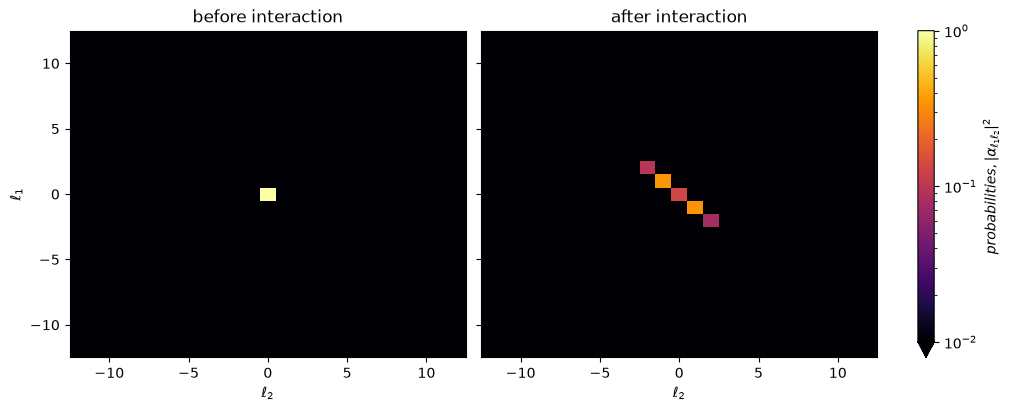

In [3]:
ls   = np.arange(-model.lmax,model.lmax+1,1)
prob_0     = ((alpha0.abs())**2).numpy()
prob_final = ((alpha.abs() )**2).numpy()


print(f'is probability conserved? -> {prob_final.sum().item():.2f} (should be ~1.0)')


prob_0     = np.where(prob_0 > 1e-5,     prob_0,    1e-5)
prob_final = np.where(prob_final > 1e-5, prob_final, 1e-5)

vmin = 1e-2
vmax = 1
fig, (ax1,ax2) = plt.subplots(1,2,sharey=True,figsize=(10,4),layout='constrained')
colormap = 'inferno'
cmsh1 = ax1.pcolormesh(ls,ls,prob_0,norm=LogNorm(vmin=vmin,vmax=vmax),cmap=colormap)
cmsh2 = ax2.pcolormesh(ls,ls,prob_final,norm=LogNorm(vmin=vmin,vmax=vmax),cmap=colormap)
fig.colorbar(cmsh2, ax = [ax1,ax2], label = r'$probabilities, |\alpha_{\ell_1 \ell_2}|^2$',extend='min')
ax1.set_ylabel(r'$\ell_1$')
ax1.set_xlabel(r'$\ell_2$')
ax2.set_xlabel(r'$\ell_2$')
ax1.set_title('before interaction')
ax2.set_title('after interaction')
plt.show()

The most significant sideband probabilities are those in the anti-diagonal $\ell_2 = -\ell_1$, which correspond to events where the electron and the lasers exchange $\ell_1$ quanta of energy $\hbar\omega_{12} = \hbar(\omega_1-\omega_2)$. As mentioned in the paper, this is a resonant process and thus it is favoured, yielding much larger probabilities than the off-resonance processes. We also see slight asymmetries related to the joint effect of the recoil effects + the Gouy phase.

Before moving on, we take a quick gradient test to check that the optimization, based on the gradient descent method, will work correctly. The test is based on a comparison between the autograd computed by PyTorch and a first order finite-difference scheme.

In [4]:
from gradient_test import gradient_test
gradient_test(model,alpha0,eps=5e-4,doc_order=1,rtol=1e-4)

parameter           analytic       numeric     rel err
log_electric      -2.414e-01    -2.414e-01    3.79e-07
log_fr_diff        3.076e-02     3.075e-02    4.22e-05
log_kinetic       -3.090e-02    -3.090e-02    3.12e-05
log_distance      -2.116e-02    -2.116e-02    4.84e-08


{'log_electric': (-0.24139636399465217,
  -0.2413962724692187,
  3.791501523430187e-07),
 'log_fr_diff': (0.030755894660471593,
  0.03075459594237273,
  4.222842339574792e-05),
 'log_kinetic': (-0.03090461415475044,
  -0.030903649445357395,
  3.121668185882005e-05),
 'log_distance': (-0.02115992884338919,
  -0.021159929867176075,
  4.838328347529262e-08)}

Ok! The gradients compare well with the numerical derivative, so we can move on to the optimization.
Note that having used a single $\epsilon$ for all four trainable parameters, means that the width normalization implemented in physics.py is working as intended, meaning the loss varies on comparable scales for every trainable parameter allowing us to use a single learning rate.

**OPTIMIZATION** 

Here, we will optimize the physical interaction parameters in order to obtain highly compressed beams. We take as a measure of compression the so-called degree of coherence 

${\rm DOC}_m = |I_m/I_0|^2$ with $ I_m = \int_{-\pi/\Omega}^{\pi/\Omega} \,{\rm e}^{m{\rm i} \Omega t}\, |\psi(z,t)|^2 dt $

where $\Omega$ is a reference frequency. The details about ${\rm DOC}_m$ can be found in the paper or in metric.py, but in short it is a quantity that compares the effect of the electron with a point-particle when interacting with a mode of frequency $m\Omega$, for a perfectly-compressed electron we get ${\rm DOC}_m = 1$, while for a very broad probability distribution we instead find ${\rm DOC}_m = 0$. 

One might wonder why we are using this complicated measure instead of just measuring the width of the peaks (using for example the full width at half max). The main difference is that the ${\rm DOC}_m$ works more like a standard deviation, in the sense that it degrades if the electron probability density has a slowly decreasing background, favouring peaks that have the highest contrast, and thus were the electron is strongly localized. 

Here, we will try to minimize a loss function defined as $L = 1-{\rm DOC}_1$, that in turn maximizes the degree of coherence (order 1). To do so, we take as our learned parameters:

1) the kinetic energy of the electron (which sets its velocity)
2) the electric field amplitude of laser 1 $(E_1)$, with the amplitude of the other laser fixed at $E_2 = E_1 (\omega_2/\omega_1)^{1/2}$ 
3) the frequency difference between the two lasers $\omega_{12} = (\omega_1-\omega_2)$ 
3) the free-propagation distance after interaction, which will tell us where the beam presents the train of pulses that are most compressed.

As explained in the paper, the ${\rm DOC}_1$ can surpass the 0.34 theoretical analytical maximum from the nonrecoil PINEM-like solution due to the recoil effects that reshape the sideband spectrum during interaction.

NOTE: the model is implemented as a differentiable PyTorch nn.Module, which is what the optimization below relies on.

We begin by showcasing the optimization algorithm with only the free-propagation distance as the learned parameter, and reuse the model from the previous example, only replacing the initial guess of the propagation distance with 0.0.

In [5]:
# we freeze the gradient of all parameters except the propagation distance 
# (the log_distance is because we actually optimize the parameters in log-scale, for more information see optimize.py)

m_sing = ElectronModulator(cfg,kinetic,electric1,freq_diff,d0,use_gouy = True)
for name, p in m_sing.named_parameters(): 
    p.requires_grad_(name == 'log_distance') 

# the interaction does ot depend on the propagation distance, so with only log_distance trainable the comb is identical at every step.
with torch.no_grad():
    alpha_int_sing = interaction(m_sing,alpha0)

steps      = 100    # number of steps in the optimization
lr         = 1e-1  # learning rate
hist_sing  = optimize(m_sing,steps,lr,ref_freq=freq_diff,alpha_int = alpha_int_sing)

The optimizer tracks the sideband leak, which is essentially checking that the probabilities inside the higher order sidebands ($|\ell_{1,2}| = \ell_{\rm max}$) remain small ($\ll 1$). This can be important because the discretization grid (sideband number, interaction extent and point density in the interaction) is frozen, so the optimization might actually introduce parameters for which the grid is not large enough. Here, the interaction parameters are not being optimized there should be no problem, but we print it as a sanity check.

NOTE: The optimizer actually has a warning built in that will let us know if the leak is larger than 1e-2. However, we can still print the maximum each time to see how close we are to this bound.

max sideband leak: 0.000000 (should be << 1)


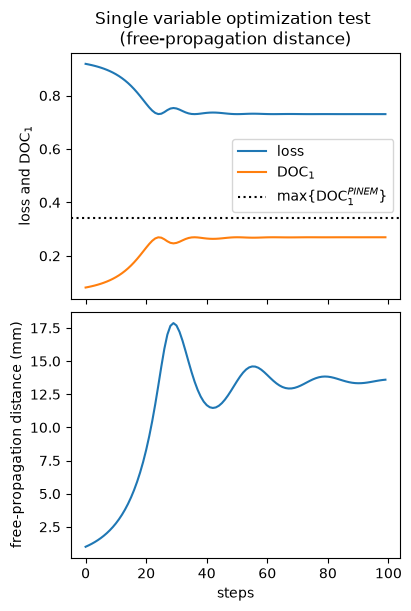

In [6]:
histarray = np.array(hist_sing)
loss_hist = histarray[:,0]
doc_hist  = histarray[:,1]
doc_sing  = doc_hist[-1]
leak      = histarray[:,2]
dist_hist = histarray[:,-1]

print(f'max sideband leak: {np.max(leak):.6f} (should be << 1)')

fig,(ax1,ax2) = plt.subplots(2,1,sharex = True,figsize = (4,6),layout='constrained')

ax1.set_title('Single variable optimization test \n' + '(free-propagation distance)')

ax1.plot(loss_hist, label = 'loss')
ax1.plot(doc_hist,label = r'${\rm DOC}_1$')
ax1.axhline(0.34,color = 'k', linestyle=':',label=r'${\rm max}\{{\rm DOC}_1^{PINEM}\}$')
ax1.set_ylabel(r'loss and ${\rm DOC}_1$')
ax1.legend()

ax2.plot(dist_hist) # the optimizer returns values in the units of the inputs!
ax2.set_xlabel('steps')
ax2.set_ylabel('free-propagation distance (mm)')
plt.show()

After around 40 steps, the optimizer seems to have converged on the loss function and the ${\rm DOC}_1$, while the distance is still slightly oscillating at the last steps. The convergence of the measure of compression is much faster than the convergence of the parameter to the final value. This can be interpreted as the temporal compression being robust against changes in the propagation distance in the order of a few millimeters.

Since the distance is the only free parameter here and enters only through the free-propagation phase, the optimum can be found by brute force, giving an independent check on the descent.

In [7]:
with torch.no_grad():
    prof = profile_distance(m_sing, alpha0, n_z=400, ref_freq=freq_diff,
                            alpha_int=alpha_int_sing)
print(f'Adam:  d = {hist_sing[-1][6]:.3f} mm, DOC_1 = {hist_sing[-1][1]:.4f}')
print(f'sweep: d = {prof.distance.item():.3f} mm, DOC_1 = {prof.doc.item():.4f}')
doc_sing  = max(doc_sing,prof.doc.item())
dist_sing = prof.distance.item()

Adam:  d = 13.599 mm, DOC_1 = 0.2695
sweep: d = 85.690 mm, DOC_1 = 0.4038


The sweep finds a maximum that is significantly better than the optimizer, telling us that while the Adam has converged it did so to a local maximum instead of the global one. This happens because the ${\rm DOC}_1$ has several maxima inside a single Talbot period. To circumvent this, we'll replace the optimization of the propagation distance with Adam, for a sweep over half the Talbot lenght (one Talbot period), while allowing the Adam optimizer to work with the other parameters.

Interestingly, it seems that our naive initial guess has actually surpassed the PINEM analytical limit (~0.34) by a bit (~0.40 with the sweep) owing to the nonrecoil and Gouy phase related effects. However, we should be able to do even better with a joint optimization of the other parameters.

In [8]:
kinetic_init   = kinetic
electric_init  = electric1
freq_diff_init = freq_diff
m_full = ElectronModulator(cfg,kinetic_init,electric_init,freq_diff_init,0.0,use_gouy = True)
# we freeze the gradient of the propagation distance, since we'll optimize it by scanning
for name, p in m_full.named_parameters(): 
    p.requires_grad_(name != 'log_distance') 
# we store the modulator and the energy matrix obtained from the initialization parameters to use later
with torch.no_grad():
    alpha_init = m_full(alpha0)
    m_init = ElectronModulator(cfg,kinetic_init,electric_init,freq_diff_init,0.0,use_gouy = True)
steps = 75
lr    = 1e-1
# with profile=True, the optimizer will optimize the propagation distance by scanning, which should avoid the problem of finding local extrema instead of a global one
cache = Path('data/joint_run.npz')
if cache.exists():
    d = np.load(cache)
    hist_tot = [tuple(r) for r in d['hist']]
    with torch.no_grad():
        m_full.log_electric.fill_(float(d['latents'][0]))
        m_full.log_kinetic.fill_( float(d['latents'][1]))
        m_full.log_fr_diff.fill_( float(d['latents'][2]))
        m_full.log_distance.fill_(float(d['latents'][3]))
    assert int(d['n_seg']) == m_full.num_segments and int(d['lmax']) == m_full.lmax, \
    'cache built with a different grid -- delete data/*.npz and re-run'
else:
    hist_tot = optimize(m_full, steps, lr, ref_freq=freq_diff, profile=True)
    latents = np.array([m_full.log_electric.item(), m_full.log_kinetic.item(),
                        m_full.log_fr_diff.item(),  m_full.log_distance.item()])
    cache.parent.mkdir(exist_ok=True)
    np.savez(cache, hist=np.array(hist_tot), latents=latents,
             n_seg=m_full.num_segments, lmax=m_full.lmax, gouy=m_full.use_gouy)
with torch.no_grad():
    prof_full = profile_distance(m_full, alpha0, n_z=400, ref_freq=freq_diff)
print(f'restored max DOC_1 = {prof_full.doc.item():.5f}  vs cached {hist_tot[-1][1]:.5f}')

restored max DOC_1 = 0.67421  vs cached 0.67419


max sideband leak: 0.003304 (should be << 1)


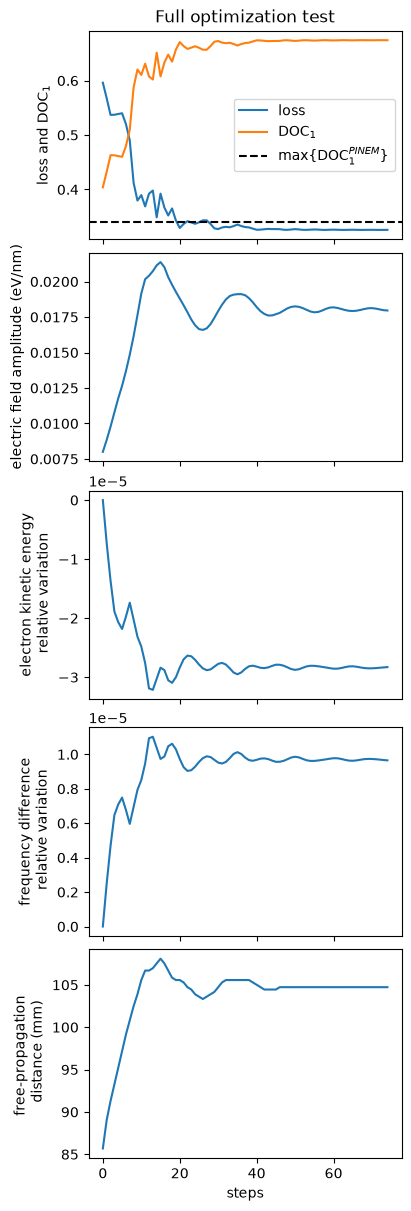

In [9]:
histarray = np.array(hist_tot)
loss_hist = histarray[:,0]
doc_hist  = histarray[:,1]
doc_full  = doc_hist[-1]
leak      = histarray[:,2]
elec_hist = histarray[:,3]
kine_hist = histarray[:,4]
diff_hist = histarray[:,5]
dist_hist = histarray[:,6]

print(f'max sideband leak: {np.max(leak):.6f} (should be << 1)')

fig,axes = plt.subplots(5,1,sharex = True,figsize = (4,12),layout='constrained')

axes[0].set_title('Full optimization test')

axes[0].plot(loss_hist,label = 'loss')
axes[0].plot(doc_hist,label = r'${\rm DOC}_1$')
axes[0].axhline(0.34,color = 'k', linestyle='--',label=r'${\rm max}\{{\rm DOC}_1^{PINEM}\}$')
axes[0].set_ylabel(r'loss and ${\rm DOC}_1$')
axes[0].legend()

axes[1].plot(elec_hist)
axes[1].set_ylabel('electric field amplitude (eV/nm)')

axes[2].plot((kine_hist/kine_hist[0]-1))
axes[2].set_ylabel('electron kinetic energy\n relative variation')

axes[3].plot(diff_hist/diff_hist[0]-1)
axes[3].set_ylabel('frequency difference\n relative variation')

axes[4].plot(dist_hist)
axes[4].set_ylabel('free-propagation \n distance (mm)')
axes[4].set_xlabel('steps')

plt.show()

With the joint optimization, we have managed tu further increase the ${\rm DOC}_1$ (and thus decrease the loss) beyond the initial value to almost double the analytical limit (~0.67)! While it is true that we could, in principle, achieve even better results but this is good enough for the purpose of this project. Increasing the compression further could require the use of higher field amplitudes, which requires a larger lmax and greatly increases the computation times.

Before moving on, it is worth mentioning the fact that the kinetic energy and the frequency difference have varied in very much opposite ways but with the same overall shape, following each other through the parameter space in order to maintain the phase-matching condition!

Now, lets do a more visual demonstration of how the optimization has improved the temporal compression. Lets look at the evolution of the electron through one period (one Talbot length) and at the optimized position of maximal compression. We'll compare the electron probability density during free-propagation in both the unoptimized initial guess and the result after optimization.

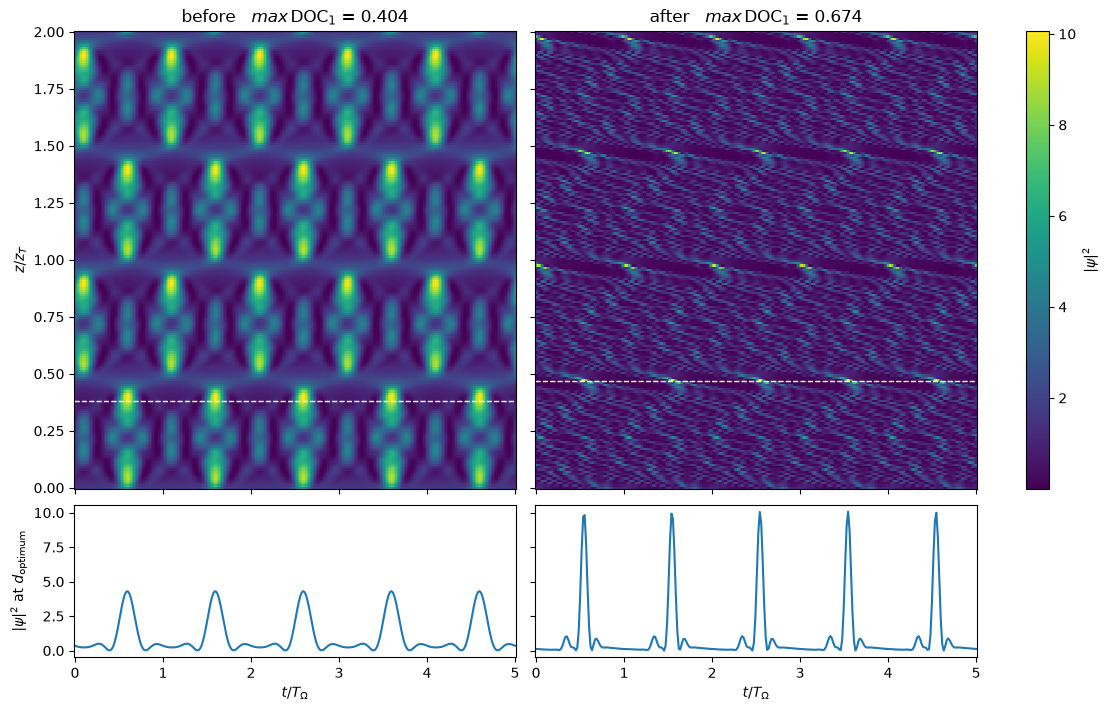

In [10]:
from scipy.constants import physical_constants
# the initial guess has already been stored in alpha_init
def propagation_map(m, alpha0, n_beats = 5, Nz = 200, Nt = 300):
    with torch.no_grad():
        alpha = interaction(m,alpha0)
        lmax,L = m.lmax,m.L
        l = torch.arange(0, L) - lmax
        l1, l2 = l[:, None], l[None, :]
        w = l1*m.frequency1 + l2*m.frequency2
        zt, dw = m.talbot_distance, m.fr_diff

        phi = (2*np.pi/zt) * w**2 * dw**-2
        z = torch.linspace(0, 2.0*zt.item(), Nz, dtype=torch.float64)
        a_z = alpha[None] * torch.exp(1j * phi[None] * z[:, None, None])

        T = (2*np.pi/dw.abs()).item()
        t = torch.linspace(0, n_beats*T, Nt, dtype=torch.float64)
        ph = torch.exp(-1j * w[None] * t[:, None, None])
        rho = torch.einsum('zij,tij->zt', a_z, ph).abs()**2  # we compute the probability density i.e. |\psi|^2
    return t.numpy()/T, z.numpy()/zt.item(), rho.numpy()

docs = [doc_sing, doc_hist[-1]]
mm_au = 1/(physical_constants['atomic unit of length'][0]*1e3)
frac = [dist_sing*mm_au/m_sing.talbot_distance.item(), dist_hist[-1]*mm_au/m_full.talbot_distance.item()]
fig, axes = plt.subplots(2,2,figsize=(11,7),sharex='col',sharey='row',
                         gridspec_kw={'height_ratios':[3,1]},layout='constrained')
for j,(m,title) in enumerate([(m_init,'before'),(m_full,'after')]):
    t, z, rho = propagation_map(m, alpha0)
    im = axes[0,j].pcolormesh(t,z,rho,shading='auto')
    axes[0,j].axhline(frac[j],color='w',ls='--',lw=1)
    axes[0,j].set_title(f'{title}   ' + r'${max \, \rm DOC}_1$ = ' + f'{docs[j]:.3f}')
    axes[1,j].plot(t, rho[int(np.argmin(np.abs(z-frac[j])))])
    axes[1,j].set_xlabel(r'$t/T_\Omega$')
axes[0,0].set_ylabel(r'$z/z_T$')
axes[1,0].set_ylabel(r'$|\psi|^2$ at $d_{\rm optimum}$')
fig.colorbar(im,ax=axes[0,:],label=r'$|\psi|^2$')
plt.show()

Above we see the electron probability density plotted as a function of the time coordinate (x-axis) and the free-propagation distance (y-axis). We can see that at periodic intervals, the electron is compressed over time into a short pulse (narrow distribution in the x-axis) at certain values of the free-propagation distance. The brighter spots represent the time where it is most likely to find an electron assuming we have an electron detector placed at that position. The brighter and narrower the spot, the higher the probability that the electron will be found at that point in space and time. This plot is an example of the so-called Talbot carpets.

Using the sweep optimization, we find the positions $d_{\rm opt}$ where the degree of coherence is maximized (the loss minimized) and thus compression is maximal. Below the colormaps, we plot the electron probability density at this optimum position as a function of time. We observe that the initial guess produces a train of compressed pulses that are localized (compressed) to a certain degree. However, for the parameters obtained through optimization we obtain even narrower pulses with a lower overall background, showing that the optimizer is working as intended. This will mean that we can more accurately predict when and where we are more likely to find an electron, meaning it behaves more like a point-particle.

As mentioned above, the degree of coherence could be even higher. However, almost doubling the ${\rm DOC}_1$ with respect to the analytical PINEM limit, already places this technique above standard compression methods in electron microscopes. What's more, it shows that the optimizer does its job of finding the relevant physical parameters that can enable improved temporal compression of free electrons near an initial guess that could be calibrated according to experimental capabilities and limitations of the user.

To end the example, we scan the trainable parameters around the values found by the optimizer to check that we are indeed at a local minimum of the loss function.

In [11]:
cache = Path('data/scans.npz')
c_K  = m_full.log_kinetic.item()
c_dw = m_full.log_fr_diff.item()
c_E  = m_full.log_electric.item()
if cache.exists():
    d = np.load(cache); scan_K, scan_dw, scan_E = d['K'], d['dw'], d['E']
else:
    scan_K  = np.array(scan_latent(m_full, alpha0, 'log_kinetic',
                                   c_K  + np.linspace(-20,20,101),
                                   ref_freq=freq_diff, n_z=200))
    scan_dw = np.array(scan_latent(m_full, alpha0, 'log_fr_diff',
                                   c_dw + np.linspace(-20,20,101),
                                   ref_freq=freq_diff, n_z=200))
    scan_E  = np.array(scan_latent(m_full, alpha0, 'log_electric',
                                   c_E  + np.linspace(-2,2,61),
                                   ref_freq=freq_diff, n_z=200))
    cache.parent.mkdir(exist_ok=True)
    np.savez(cache, K=scan_K, dw=scan_dw, E=scan_E)
print(f'max leak across scans: '
      f'{max(s[:,5].max() for s in (scan_K,scan_dw,scan_E)):.2e}')

max leak across scans: 1.99e-02


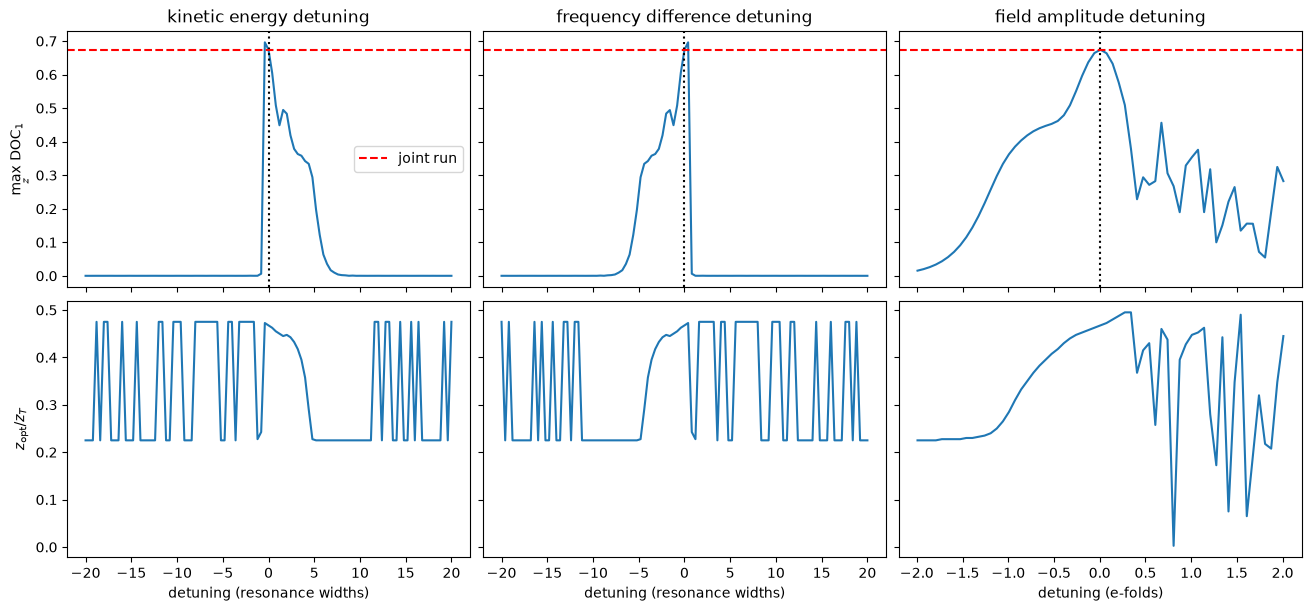

In [12]:
fig, axes = plt.subplots(2,3,figsize=(13,6),sharex='col',sharey='row',
                         layout='constrained')
panels = [(scan_K,  c_K,  'kinetic energy',       'resonance widths'),
          (scan_dw, c_dw, 'frequency difference', 'resonance widths'),
          (scan_E,  c_E,  'field amplitude',      'e-folds')]
for j,(sc,ctr,lab,unit) in enumerate(panels):
    u, doc, zfrac = sc[:,0]-ctr, sc[:,2], sc[:,4]
    axes[0,j].plot(u,doc)
    axes[0,j].axvline(0,color='k',ls=':')
    axes[0,j].axhline(hist_tot[-1][1],color='r',ls='--',
                      label='joint run' if j==0 else None)
    axes[0,j].set_title(f'{lab} detuning')
    axes[1,j].plot(u,zfrac)
    axes[1,j].set_xlabel(f'detuning ({unit})')
axes[0,0].set_ylabel(r'$\max_z\,{\rm DOC}_1$')
axes[1,0].set_ylabel(r'$z_{\rm opt}/z_T$')
axes[0,0].legend()
plt.show()

Indeed, the optimizer has landed on a local maximum and we can see that parameters in a few widths of the log-scale trainable parameters do not improve the ${DOC}_1$ futher.